In [1]:
import sys
sys.path.insert(0, '..')

In [2]:
# Basic imports
import jax.numpy as np
import jax.random as jr
import jax.scipy as jsp
import jax
import numpy

jax.config.update("jax_enable_x64", True)


# Optimisation imports
import zodiax as zdx
import optax
import optimistix as optx

# dLux imports
import dLux as dl
import dLux.utils as dlu

# Visualisation imports
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib
import chainconsumer as cc


%matplotlib inline
plt.rcParams['image.cmap'] = 'inferno'
plt.rcParams["font.family"] = "serif"
plt.rcParams["image.origin"] = 'lower'
plt.rcParams['figure.dpi'] = 72
plt.rcParams["font.size"] = 24

from detectors import *
from apertures import *
from models import *
from stats import posterior
from fitting import *
from plotting import *
from spectra import *

import interpax as ipx


In [ ]:
wid = 64
oversample = 4
pad = 2      # as calibrator-joint: 2 extra detector pixels each side, cropped after resampling

nwavels = 200
npoly = 8

wpca_file = "../data/wavefront_pca.npz"
wpca = np.load(wpca_file)
n_wpca = wpca["modes"].shape[0]
n_modes = int(round(wpca["mean"].size**0.5))   # the fits' Fourier grid (48 in the current calibrator-joint)
n_zernikes = 50                                 # as calibrator-joint; the PCA removed this span (calibrator-pca)

# The calibrator-joint model with the high-order wavefront replaced by the calibrator PCA (mean + n_wpca modes).
# No amplitude map: the current calibrator fits do not fit one, so there is no amplitude PCA
optics = NICMOSFresnelCoronagraph(512, wid, oversample, n_modes=n_modes, n_zernikes=n_zernikes, n_nodes=20,
                                  wavefront_pca=wpca_file, pad=pad)
detector = NICMOSDetector(oversample, wid, pad=pad)

vects = np.load(f"../data/iterative_spectrum_basis_F160W_{nwavels}.npy")[:, :npoly]
assert vects.shape == (nwavels, npoly)
spectrum_basis = vects/np.sqrt(np.mean(vects**2, axis=0))

ddir = '../data/NICMOS-LAPL-DD2/LAPL_DATA_DD2/comtemp_flats-DD2/'

# calibrator-joint's keys, with the PCA coefficients per visit as primary_opd is there
class WavefrontPCAFit(SinglePointFit):
    PARAM_KEYS = SinglePointFit.PARAM_KEYS | {"cold_mask_shift": "exposure", "cold_mask_tilt": "exposure",
                                              "primary_wpca": "visit", "cold_mask_opd": "exposure", "defocus3": "exposure"}

exposures_single = [
    exposure_from_file(ddir + 'n9p510kxq_o_clc_calf.fits', WavefrontPCAFit(spectrum_basis, "F110W"), crop=wid, extra_bad=None, hole_margin=0.1),
    # exposure_from_file(ddir + 'n8zu85ndq_m_clc_calf.fits', WavefrontPCAFit(spectrum_basis, "F160W"), crop=wid, extra_bad=None, hole_margin=0.1),
]


In [4]:
for exp in exposures_single:
    print(exp.target)

PSF-5-K0


In [5]:
optical_params = np.load("../data/calibrator_optical_params.npy", allow_pickle=True)[()]
per_exposure_init = ["cold_mask_shift", "cold_mask_opd", "defocus1", "defocus2"]   # medians as starting values

params = {k: {} for k in ["spectrum", "primary_wpca", "primary_low", "primary_tilt", "cold_mask_tilt", "bias"] + per_exposure_init}
for exp in exposures_single:
    key = lambda k: exp.fit.get_key(exp, k)
    params["spectrum"][key("spectrum")] = np.zeros(npoly).at[0].set(1.)          # rescaled below
    params["primary_tilt"][key("primary_tilt")] = np.array([-0.05, -0.75])*0.075
    params["cold_mask_tilt"][key("cold_mask_tilt")] = hole_tilt(exp)             # as calibrator-joint
    params["primary_wpca"][key("primary_wpca")] = np.zeros(n_wpca)               # 0 = the calibrators' mean wavefront
    params["primary_low"][key("primary_low")] = np.zeros(n_zernikes)
    params["bias"][key("bias")] = 0.
    for k in per_exposure_init:
        params[k][key(k)] = np.asarray(optical_params[k]["global"])

params |= {k: v for k, v in optical_params.items() if k not in per_exposure_init}

model_single = set_array(NICMOSModel(exposures_single, params, optics, detector))
params = ModelParams(params)

# Star flux: match the total flux of the data over the unmasked pixels (as aumic-f180m)
render = eqx.filter_jit(lambda m, e: e.fit(m, e))
star = [render(params.inject(model_single), e) for e in exposures_single]
c = sum(np.nansum(np.where(e.bad, 0., e.data)) for e in exposures_single) / sum(np.nansum(np.where(e.bad, 0., s)) for e, s in zip(exposures_single, star))
params = ModelParams(params.params | {"spectrum": jax.tree.map(lambda s: s*c, params.params["spectrum"])})


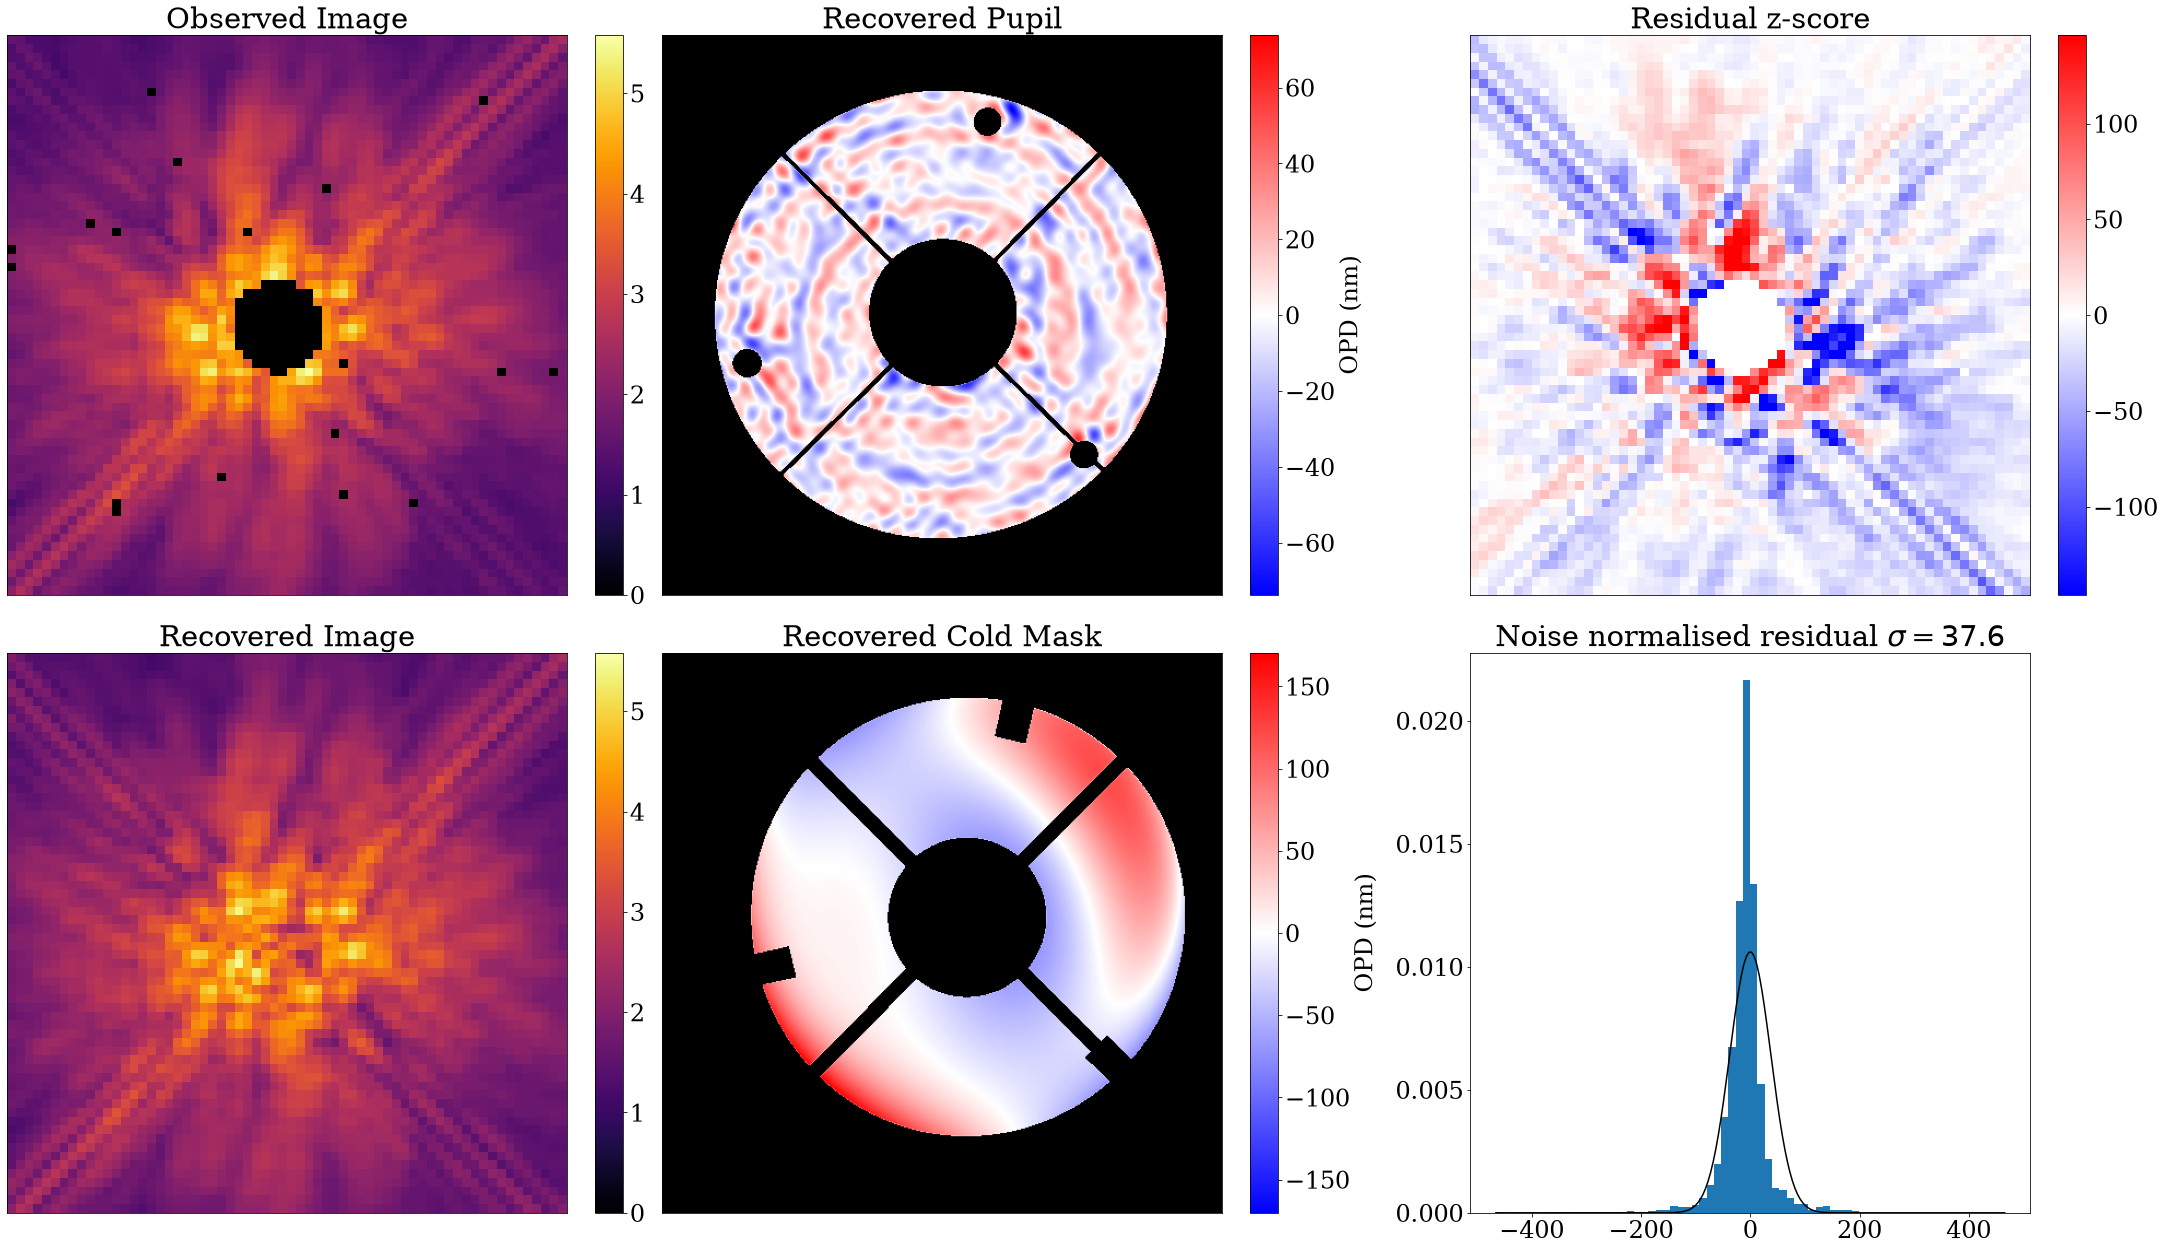

In [6]:
plot_comparison(model_single, params, exposures_single, percentile=99, wf_size=512)

In [7]:
g = 5e-2
things_start = {
    "spectrum": sgd(g*3, 30.),
    "primary_tilt": sgd(g*5, 15.),
    "cold_mask_tilt": sgd(g*5, 0),
    "cold_mask_opd": sgd(g*0.1, 40),
    "defocus1": sgd(g*1, 60),
    "defocus2": sgd(g*10, 60),
    # "defocus3": sgd(g*1, 60),
    "bias": sgd(g*3, 50),
    "cold_mask_shift": sgd(g*0.5, 70),
    "primary_low": sgd(g*5., 150),
    "primary_wpca": sgd(g*5, 100),
    # global optical state fixed at the calibrator medians; free some (e.g. occulter_radius) if the fit needs it
}


In [8]:
orig_params = params.params
opt_params = set_array({k:orig_params[k] for k in orig_params if k in things_start})

In [ ]:
losses, params_history = optimise_new(
    opt_params, model_single, exposures_single, things_start, 300,
    precond_method="gn_probe", precond_kwargs=dict(n_probes=32, chunk=4, per_block=True))

  0%|          | 0/300 [00:00<?, ?it/s]

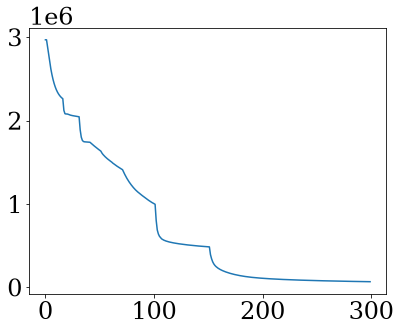

In [ ]:
plt.plot(losses[:])

In [ ]:
params_history

ParamsHistory(n_steps=300, n_params=191)

In [ ]:
list(things_start.keys())

['spectrum',
 'primary_tilt',
 'cold_mask_tilt',
 'cold_mask_opd',
 'defocus1',
 'defocus2',
 'defocus3',
 'bias',
 'cold_mask_shift',
 'primary_low',
 'primary_klip']

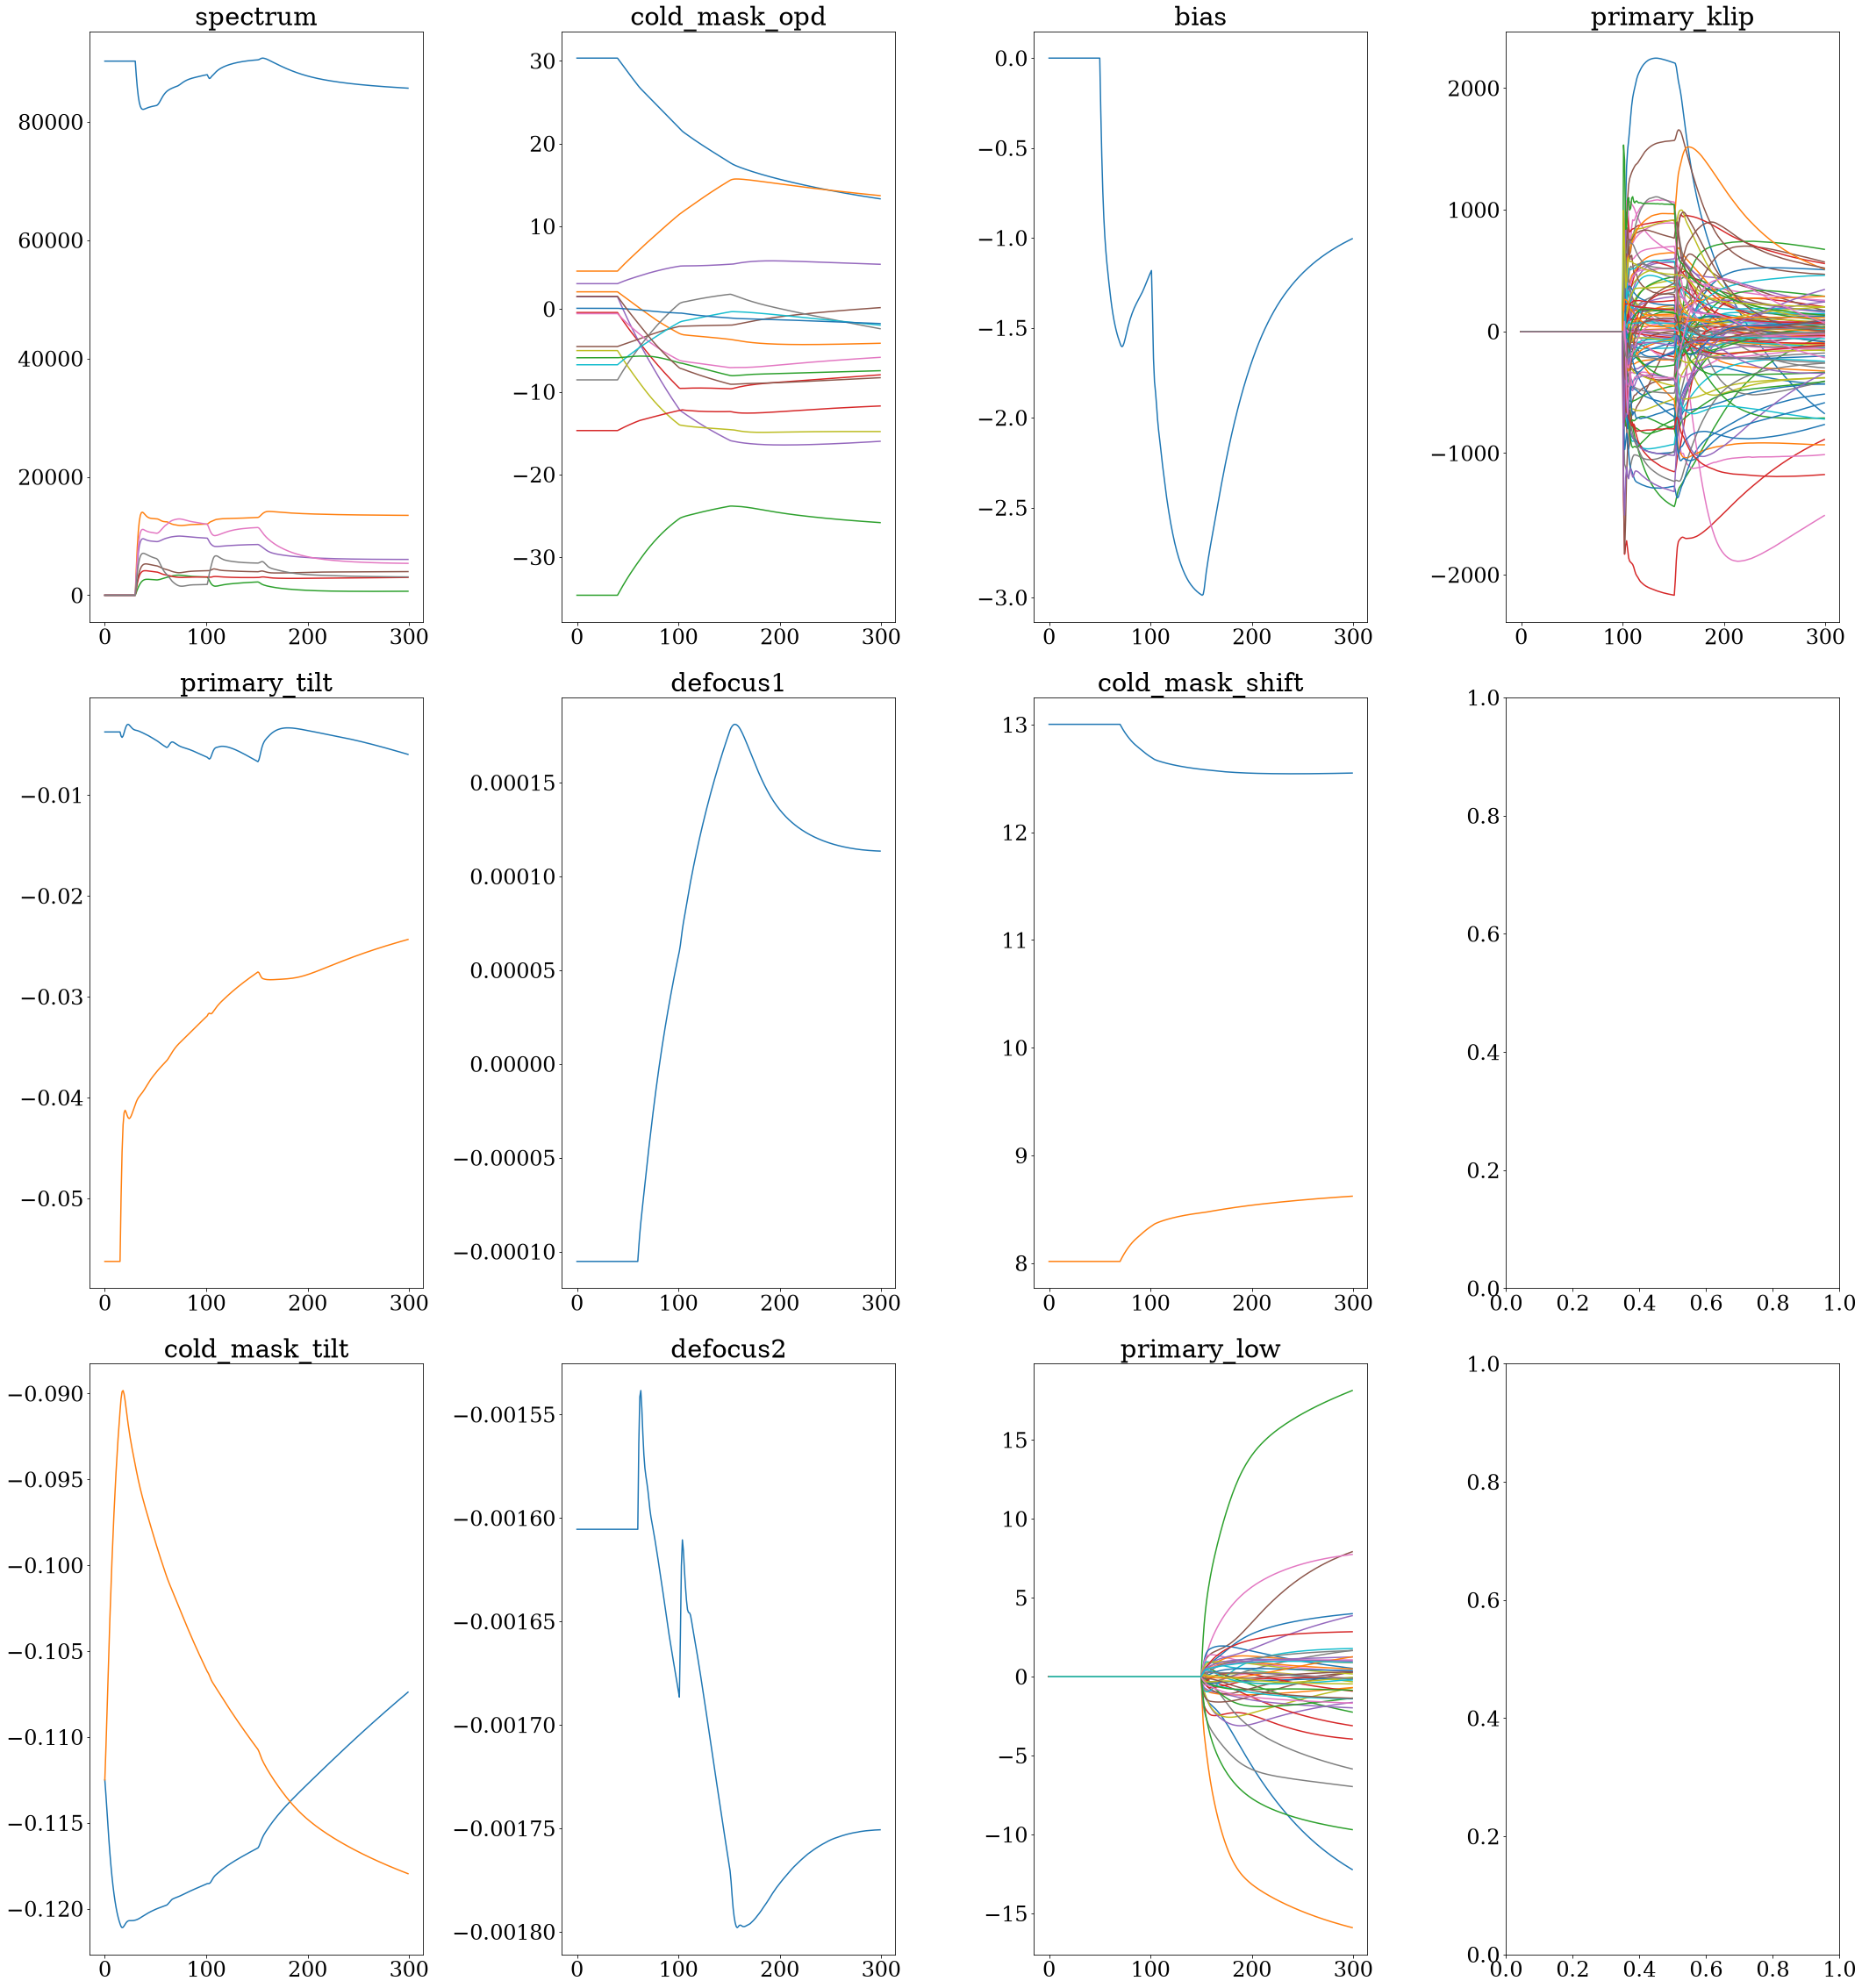

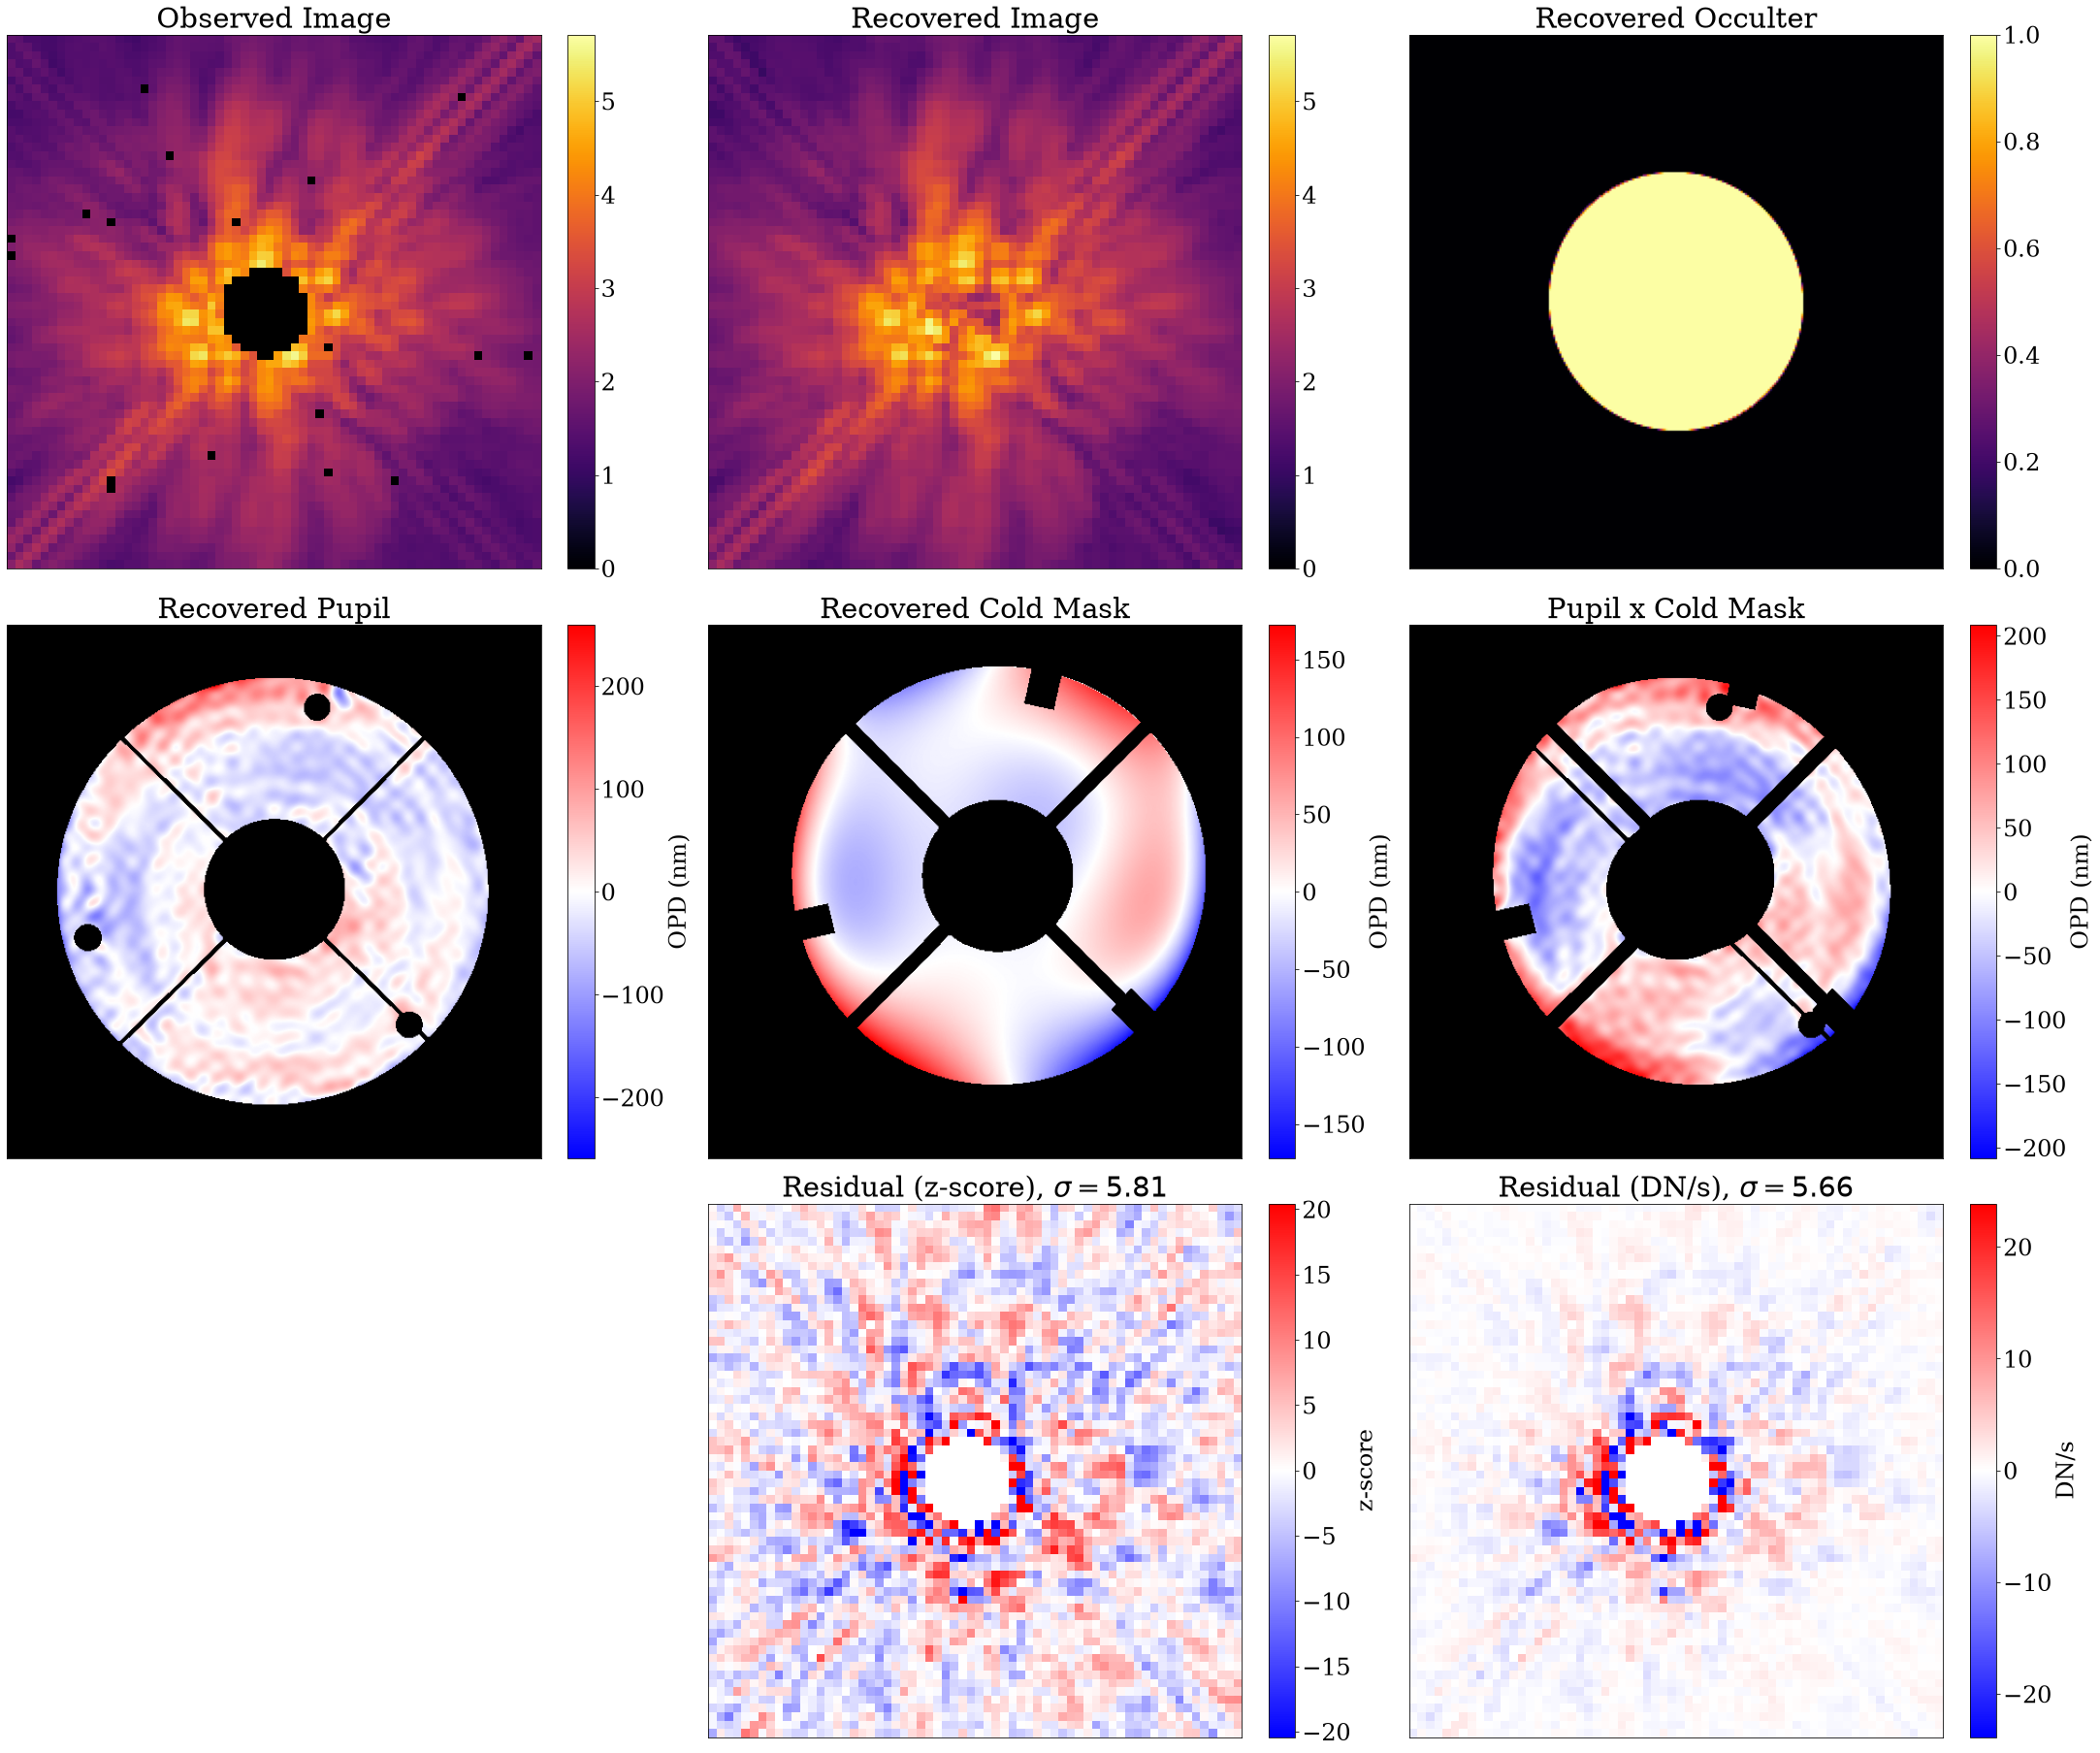

In [ ]:
# plot_params(params_history, , xw = 3)
plot_params(params_history, list(things_start.keys()), xw = 3)
plot_comparison_detailed(model_single, ModelParams(params_history[-1]), exposures_single, quadrature=False, wf_size=512, percentile=99)

In [ ]:
params.params

{'spectrum': {'PSF-5-K0_F160W': Array([90247.16314201,     0.        ,     0.        ,     0.        ,
             0.        ,     0.        ,     0.        ,     0.        ],      dtype=float64)},
 'primary_klip': {'n8zu85': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0.], dtype=float64)},
 'primary_low': {'n8zu85ncq': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      d